# Traffic-Law QA — Text Retrieval Baselines / Đối chứng truy hồi văn bản

**Trương Minh Hoàng · MSSV 25410008 · UIT group coursework**

Tách riêng bước truy hồi để đo TF-IDF và BM25 bằng cặp `(law_id, article_id)`, trước khi đánh giá
generation/OCR/ảnh. Dữ liệu VLSP là snapshot học thuật, chưa xác nhận hiệu lực pháp lý hiện hành.
Notebook không sinh tư vấn pháp luật.

Provide `TRAFFIC_LAW_JSON` and `TRAFFIC_QUESTIONS_JSON` for a replay of the labeled training questions.
Otherwise the notebook uses three fictional text records as a software smoke test.

In [1]:
from pathlib import Path
import os, sys, json
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from retrieval_baseline import evaluate,run_files,sample_data,TextRetriever,ranking_metrics
law_path=os.environ.get('TRAFFIC_LAW_JSON');question_path=os.environ.get('TRAFFIC_QUESTIONS_JSON')
if law_path and question_path:
    result=run_files(law_path,question_path)
else:
    articles,questions=sample_data();result=evaluate(articles,questions);result['scope']='SYNTHETIC_SMOKE'
print('Scope:',result['scope'])
display(pd.Series({k:v for k,v in result.items() if k not in ['metrics','source_sha256']}))


Scope: DEV_REPLAY_TEXT_ONLY


scope                                                                    DEV_REPLAY_TEXT_ONLY
articles                                                                                  395
questions                                                                                 530
labeled_questions                                                                         530
questions_with_unknown_article_reference                                                   40
queries_with_image_reference                                                              530
uses_question_text_only                                                                  True
uses_choices                                                                            False
uses_images                                                                             False
fits_to_question_labels                                                                 False
generation                                                  

## 1. Metric đúng với nhãn truy hồi / Retrieval metrics
Precision@1 kiểm tra bài đứng đầu; Recall@5 tính đủ các điều liên quan; MRR@10 lấy nghịch đảo vị trí đúng đầu tiên. Không dùng so khớp nguyên chuỗi câu trả lời để thay các chỉ số này.

In [2]:
example=ranking_metrics(['unrelated','law-A','law-A','law-B'],{'law-A','law-B','law-C'})
assert example['precision_at_1']==0 and example['recall_at_5']==2/3 and example['mrr_at_10']==.5
display(pd.Series(example))


precision_at_1    0.000000
recall_at_5       0.666667
mrr_at_10         0.500000
dtype: float64

## 2. Kết quả / Results
Các tham số được cố định trước lượt chạy. Nếu dùng file train của VLSP, số dưới đây là **DEV_REPLAY_TEXT_ONLY**: có câu hỏi tham chiếu ảnh nhưng ảnh không được dùng, không phải điểm thi hay đánh giá đa phương thức.

,precision_at_1,recall_at_5,mrr_at_10
tfidf,0.10755,0.13750,0.17891
bm25,0.06038,0.10634,0.11670


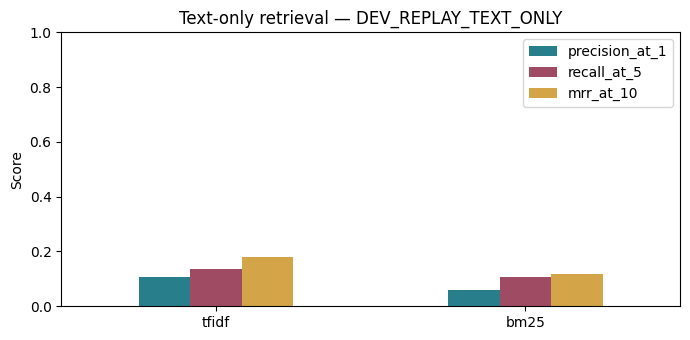

In [3]:
metrics=pd.DataFrame(result['metrics']).T
display(metrics.round(5))
fig,ax=plt.subplots(figsize=(7,3.5))
metrics.plot.bar(ax=ax,color=['#287f8b','#a04b64','#d3a548'],rot=0)
ax.set(title='Text-only retrieval — '+result['scope'],ylabel='Score',ylim=(0,1))
ax.legend(loc='upper right');fig.tight_layout();plt.show()


## 3. Giới hạn và lưu bằng chứng / Scope and evidence
Cross-encoder, OCR/ảnh và generation chưa được chạy trong đợt này. Các chỉ số 0,72/0,88/92% trong báo cáo nhóm thuộc thiết lập khác, chưa được tái lập bởi notebook này. Không điều chỉnh tham số theo bảng kết quả hiện tại.

In [4]:
LAB_RESULT={'status':'PASS',**result}
(ROOT/'evidence').mkdir(exist_ok=True)
name='text_retrieval_replay.json' if result['scope']=='DEV_REPLAY_TEXT_ONLY' else 'synthetic_smoke.json'
(ROOT/'evidence'/name).write_text(json.dumps(LAB_RESULT,indent=2,ensure_ascii=False)+'\n')
print('Saved evidence/'+name)


Saved evidence/text_retrieval_replay.json
